# 11b v2: Tourism Monthly, cenários adversos (Fase 4b)

Mesmo protocolo dos cenários do M4 v2 (`08_cenarios_adversos_v2.ipynb`): os 9 cenários do NB08, perturbação **só no treino** de cada janela (estatísticas do próprio treino, semente por série, janela e cenário), avaliação contra o **teste limpo**, mesmas 200 séries e janelas da linha de base (H = 24). ΔMAPE em % relativo e em p.p. absolutos, mediana das diferenças pareadas e IC de 95% por bootstrap pareado por série (2000).

- **SARIMA automático**: fora dos cenários adversos, pela mesma restrição operacional do M4 (a linha de base limpa levou 33 min; os 9 cenários custariam cerca de 5 h).
- **SARIMA heurístico**: reportado com e sem as janelas de fallback e sem as janelas explosivas.
- Categorias de robustez (estilo da Tabela 4): os mesmos limiares absolutos do M4. Eles foram definidos depois de ver os resultados do M4, mas **antes** desta execução do Tourism.

In [1]:
import sys, json, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

_root = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in (_root, *_root.parents) if (c / 'src' / 'pipeline_v2.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src import pipeline_v2 as pv

V2 = PROJECT_ROOT / 'results' / 'v2'
BASE = V2 / 'tm'
DIR_ADV = BASE / 'adversos'; DIR_ADV.mkdir(parents=True, exist_ok=True)
MODELOS = pv.MODELOS_RAPIDOS
TRIVIAIS = ['persistence', 'seasonal_naive', 'mean']
NOMES = {'holt_winters': 'Holt-Winters', 'persistence': 'Persistência', 'ses': 'SES', 'gbt': 'Gradient Boosting',
         'sarima_heuristic': 'SARIMA heurístico', 'random_forest': 'Random Forest', 'seasonal_naive': 'Sazonal ingênuo',
         'svr': 'SVR', 'mean': 'Média histórica'}
DESC = {c: v[2] for c, v in pv.CENARIOS.items()}
TIPO = {'ruido': 'Ruído', 'ausencia': 'Ausências', 'outlier': 'Outliers', 'trunca': 'Truncamento'}
pd.set_option('display.width', 400); pd.set_option('display.max_colwidth', 40)

def carregar(raiz, pasta):
    d = pd.concat([pd.read_csv(a) for a in sorted((raiz / pasta).glob('*_by_window.csv'))], ignore_index=True)
    return d[d['model'].isin(MODELOS)]

base = carregar(BASE, 'limpo')
adv = {c: carregar(BASE, c) for c in pv.CENARIOS}
for c, d in adv.items():
    assert d.model.nunique() == len(MODELOS) and d.unique_id.nunique() == 200, c
print(f'Tourism: linha de base {len(base):,} janelas | {len(adv)} cenários x {len(MODELOS)} modelos | H=24')

Tourism: linha de base 5,400 janelas | 9 cenários x 9 modelos | H=24


## 1. Status por cenário (fallback, erros, explosivas)

In [2]:
linhas = []
for c, d in [('limpo', base), *adv.items()]:
    t = pv.taxas_status(d)
    for m in MODELOS:
        linhas.append({'cenario': c, 'modelo': NOMES[m], 'fallback (%)': 100 * (t.loc[m, pv.FB_SNAIVE] + t.loc[m, pv.FB_MEAN]),
                       'erro (%)': 100 * t.loc[m, pv.ERRO], 'explosivas (n)': int(pv.flag_explosiva(d[d.model == m]).sum())})
status = pd.DataFrame(linhas); status.to_csv(DIR_ADV / 'tm_adversos_status.csv', index=False)
print('Fallback (% das janelas):')
print(status.pivot(index='cenario', columns='modelo', values='fallback (%)').round(1).to_string())
print('\nErros:', int((status['erro (%)'] > 0).sum()), '| explosivas por modelo:',
      status.groupby('modelo')['explosivas (n)'].sum()[lambda s: s > 0].to_dict())

Fallback (% das janelas):
modelo             Gradient Boosting  Holt-Winters  Média histórica  Persistência  Random Forest  SARIMA heurístico  SES  SVR  Sazonal ingênuo
cenario                                                                                                                                       
A_ruido_10pct                    0.0           0.0              0.0           0.0            0.0               33.3  0.0  0.0              0.0
A_ruido_30pct                    0.0           0.0              0.0           0.0            0.0               33.3  0.0  0.0              0.0
B_ausencias_10pct                0.0           0.0              0.0           0.0            0.0               33.3  0.0  0.0              0.0
B_ausencias_20pct                0.0           0.0              0.0           0.0            0.0               33.3  0.0  0.0              0.0
B_ausencias_30pct                0.0           0.0              0.0           0.0            0.0               33.3 

## 2. Degradação: ΔMAPE por modelo e cenário

In [3]:
bs_base = pv.agregar_por_serie(base)
bs_adv = {c: pv.agregar_por_serie(d) for c, d in adv.items()}
delta = pd.concat([pv.tabela_delta(bs_base, bs_adv[c]).reset_index().assign(cenario=c) for c in pv.CENARIOS], ignore_index=True)
delta.to_csv(DIR_ADV / 'tm_adversos_delta_longo.csv', index=False)

def pivot(col, d=delta, modelos=MODELOS):
    p = d.pivot(index='cenario', columns='model', values=col).loc[list(pv.CENARIOS)]
    p.index = [DESC[c] for c in p.index]
    p = p[[m for m in modelos if m in p.columns]]
    p.columns = [NOMES[m] for m in p.columns]
    return p

d_pct, d_pp, d_par = pivot('delta_pct').round(1), pivot('delta_pp').round(2), pivot('delta_pp_pareado_mediana').round(2)
for nome, tab in [('ΔMAPE relativo (%)', d_pct), ('ΔMAPE absoluto (p.p.)', d_pp), ('Mediana das diferenças pareadas (p.p.)', d_par)]:
    print(f'=== {nome} | positivo = degradação ==='); print(tab.to_string()); print()
d_pct.to_csv(DIR_ADV / 'tm_adversos_delta_pct.csv'); d_pp.to_csv(DIR_ADV / 'tm_adversos_delta_pp.csv'); d_par.to_csv(DIR_ADV / 'tm_adversos_delta_pareado.csv')

=== ΔMAPE relativo (%) | positivo = degradação ===
                 Persistência  Média histórica  Sazonal ingênuo  SES  Holt-Winters  SARIMA heurístico  Random Forest  Gradient Boosting   SVR
Ruído σ=10%              -0.3              0.0              4.5  0.3           6.8                3.4           -1.6                0.4   2.2
Ruído σ=30%               1.4              0.2             18.2 -2.1          14.3                9.2           -0.6                8.0   8.2
Ausências 10%            -0.7             -0.3              2.3 -1.0           4.7                0.6            1.1                1.9   2.2
Ausências 20%             2.2             -0.7              9.9  1.5          15.0                4.8            5.8                7.2   7.7
Ausências 30%             0.9             -1.1              8.6  4.4          17.8                7.4            9.9               13.6  13.0
Outliers 2%               3.8             -1.5              8.5 -2.2          20.7               

### 2.1 SARIMA heurístico: com e sem fallback e sem explosivas
"Sem fallback" exclui as janelas em que o SARIMA heurístico caiu no sazonal ingênuo (toda a 1ª janela e as de verossimilhança degenerada após truncamento), na linha de base **e** no cenário; "sem explosivas" exclui as janelas sinalizadas.

In [4]:
def delta_variante(incluir_fallback, excluir_explosivas):
    b = pv.agregar_por_serie(base, incluir_fallback, excluir_explosivas)
    return pd.concat([pv.tabela_delta(b, pv.agregar_por_serie(adv[c], incluir_fallback, excluir_explosivas)).reset_index().assign(cenario=c)
                      for c in pv.CENARIOS], ignore_index=True)
var = {'com fallback': delta, 'sem fallback': delta_variante(False, False), 'sem explosivas': delta_variante(True, True)}
sar = pd.DataFrame({v: d[d.model == 'sarima_heuristic'].set_index('cenario')['delta_pct'] for v, d in var.items()}).loc[list(pv.CENARIOS)]
sar['n séries (sem fallback)'] = var['sem fallback'][var['sem fallback'].model == 'sarima_heuristic'].set_index('cenario')['n_series']
sar.index = [DESC[c] for c in sar.index]
print('SARIMA heurístico, Δ% relativo:'); print(sar.round(1).to_string())
sar.to_csv(DIR_ADV / 'tm_adversos_sarima_variantes.csv')

SARIMA heurístico, Δ% relativo:
                 com fallback  sem fallback  sem explosivas  n séries (sem fallback)
Ruído σ=10%               3.4           3.6             3.4                      200
Ruído σ=30%               9.2           7.7             9.2                      200
Ausências 10%             0.6           6.3             0.6                      200
Ausências 20%             4.8          12.6             4.8                      200
Ausências 30%             7.4          10.8             7.4                      200
Outliers 2%               7.6           6.0             7.6                      200
Outliers 5%              19.4          18.5            19.4                      200
Truncamento 50%           3.2           2.4             3.2                      200
Truncamento 25%           0.0           2.2             0.0                      199


## 3. Incerteza: IC de 95% por bootstrap pareado por série

In [5]:
ics, pares = [], []
for c in pv.CENARIOS:
    t, p = pv.bootstrap_delta(bs_base, bs_adv[c], MODELOS, n=2000)
    ics.append(t.assign(cenario=c)); pares.append(p.assign(cenario=c))
ic = pd.concat(ics).reset_index().rename(columns={'index': 'model'}); par = pd.concat(pares, ignore_index=True)
ic.to_csv(DIR_ADV / 'tm_adversos_delta_ic95.csv', index=False); par.to_csv(DIR_ADV / 'tm_adversos_pares_ic95.csv', index=False)
fmt = ic.assign(txt=lambda d: d.apply(lambda r: f"{r.delta_pct:+.1f} [{r.ic_pct_inf:+.1f}; {r.ic_pct_sup:+.1f}]" + (' ~0' if r.ic_inclui_zero else ''), axis=1))
tab_ic = fmt.pivot(index='cenario', columns='model', values='txt').loc[list(pv.CENARIOS), MODELOS]
tab_ic.index = [DESC[c] for c in tab_ic.index]; tab_ic.columns = [NOMES[m] for m in tab_ic.columns]
print('Δ% [IC 95%]; "~0" = IC inclui zero'); print(tab_ic.to_string()); print()
print(f'Modelo x cenário com IC incluindo zero: {int(ic.ic_inclui_zero.sum())} de {len(ic)}')
aj = [m for m in MODELOS if m not in TRIVIAIS]
pa = par[par.modelo_a.isin(aj) & par.modelo_b.isin(aj)]
print(f'Pares de modelos AJUSTADOS distinguíveis (IC da diferença exclui zero): {int((~pa.ic_inclui_zero).sum())} de {len(pa)}')
for c in pv.CENARIOS:
    s = pa[(pa.cenario == c) & ~pa.ic_inclui_zero]
    if len(s):
        print(f'  {DESC[c]:<16}: ' + ', '.join(f'{NOMES[a]} ≠ {NOMES[b]}' for a, b in zip(s.modelo_a, s.modelo_b)))

Δ% [IC 95%]; "~0" = IC inclui zero
                         Persistência       Média histórica        Sazonal ingênuo                    SES           Holt-Winters      SARIMA heurístico          Random Forest      Gradient Boosting                   SVR
Ruído σ=10%      -0.3 [-4.4; +3.4] ~0  +0.0 [-1.4; +0.5] ~0   +4.5 [-2.7; +9.3] ~0   +0.3 [-2.8; +2.7] ~0  +6.8 [-0.7; +14.4] ~0   +3.4 [-2.4; +7.6] ~0   -1.6 [-5.0; +6.2] ~0   +0.4 [-4.8; +9.0] ~0  +2.2 [-2.7; +4.5] ~0
Ruído σ=30%      +1.4 [-2.0; +6.6] ~0  +0.2 [-1.4; +2.7] ~0    +18.2 [+7.5; +23.6]   -2.1 [-6.8; +3.2] ~0    +14.3 [+3.8; +24.0]     +9.2 [+2.8; +18.7]  -0.6 [-3.9; +11.1] ~0     +8.0 [+1.8; +18.7]    +8.2 [+1.4; +13.0]
Ausências 10%    -0.7 [-4.3; +2.4] ~0  -0.3 [-2.9; +0.8] ~0  +2.3 [-1.2; +11.1] ~0   -1.0 [-3.7; +5.2] ~0  +4.7 [-3.3; +13.6] ~0   +0.6 [-5.2; +6.8] ~0  +1.1 [-1.1; +11.6] ~0  +1.9 [-1.4; +10.5] ~0  +2.2 [-2.0; +7.1] ~0
Ausências 20%    +2.2 [-3.5; +5.4] ~0  -0.7 [-3.1; +1.3] ~0     +9.9 [+2.0; +15.7]   

## 4. Hierarquia de robustez (baselines triviais separados)
Δ% médio por tipo de cenário **com sinal** e escore = média de |Δ%| nos 9 cenários; rank dentro de cada grupo.

In [6]:
delta['tipo'] = delta['cenario'].map(lambda c: TIPO[pv.CENARIOS[c][0]])
por_tipo = delta.pivot_table(index='model', columns='tipo', values='delta_pct', aggfunc='mean')[list(TIPO.values())]
por_tipo_pp = delta.pivot_table(index='model', columns='tipo', values='delta_pp', aggfunc='mean')[list(TIPO.values())]
escore = delta.groupby('model')['delta_pct'].apply(lambda x: x.abs().mean())
hier = por_tipo.round(1).add_suffix(' Δ%').join(por_tipo_pp.round(2).add_suffix(' Δp.p.'))
hier['Δ% médio (com sinal)'] = delta.groupby('model')['delta_pct'].mean().round(1)
hier['Escore |Δ%| médio'] = escore.round(1)
hier['Grupo'] = ['Baseline trivial' if m in TRIVIAIS else 'Modelo ajustado' for m in hier.index]
hier['Rank robustez'] = hier.groupby('Grupo')['Escore |Δ%| médio'].rank(method='min').astype(int)
hier = hier.sort_values(['Grupo', 'Rank robustez'], ascending=[False, True])
hier_m = hier.copy(); hier_m.index = [NOMES[m] for m in hier.index]
for g, titulo in [('Modelo ajustado', 'Modelos ajustados'), ('Baseline trivial', 'Baselines triviais')]:
    print(f'=== {titulo} ==='); print(hier_m[hier_m.Grupo == g].drop(columns='Grupo').to_string()); print()
hier_m.to_csv(DIR_ADV / 'tm_adversos_hierarquia_robustez.csv')

cat = por_tipo.apply(lambda s: s.map(lambda d: 'Melhora*' if d <= -2 else 'Alta' if d < 2 else 'Moderada' if d < 10 else 'Baixa'))
cat_txt = pd.DataFrame({tp: [f'{cat.loc[m, tp]} ({por_tipo.loc[m, tp]:+.1f}%)' for m in MODELOS] for tp in TIPO.values()},
                       index=[NOMES[m] for m in MODELOS])
print('Categorias (mesmos limiares do M4): Alta |Δ%|<2; Moderada 2 a <10; Baixa >=10; Melhora* <= −2')
print(cat_txt.to_string()); cat_txt.to_csv(DIR_ADV / 'tm_adversos_categorias.csv')

=== Modelos ajustados ===
tipo               Ruído Δ%  Ausências Δ%  Outliers Δ%  Truncamento Δ%  Ruído Δp.p.  Ausências Δp.p.  Outliers Δp.p.  Truncamento Δp.p.  Δ% médio (com sinal)  Escore |Δ%| médio  Rank robustez
SES                    -0.9           1.6         -1.2             0.2        -0.31             0.55           -0.41               0.08                   0.1                1.5              1
Random Forest          -1.1           5.6          4.3            -1.0        -0.29             1.46            1.12              -0.27                   2.4                3.4              2
SVR                     5.2           7.6          8.9             0.4         1.34             1.95            2.26               0.11                   5.8                6.1              3
SARIMA heurístico       6.3           4.3         13.5             1.6         1.49             1.01            3.21               0.38                   6.2                6.2              4
Gradient Boost

## 5. Comparação com o M4 v2 (mesmos cenários, mesmos modelos)

In [7]:
m4d = pd.read_csv(V2 / 'm4' / 'adversos' / 'm4_adversos_delta_longo.csv')
m4ic = pd.read_csv(V2 / 'm4' / 'adversos' / 'm4_adversos_delta_ic95.csv')
j = delta.merge(m4d[['model', 'cenario', 'delta_pct', 'delta_pp']], on=['model', 'cenario'], suffixes=('_tm', '_m4'))
j = j.merge(ic[['model', 'cenario', 'ic_inclui_zero']].rename(columns={'ic_inclui_zero': 'IC~0 TM'}), on=['model', 'cenario'])
j = j.merge(m4ic[['model', 'cenario', 'ic_inclui_zero']].rename(columns={'ic_inclui_zero': 'IC~0 M4'}), on=['model', 'cenario'])
comp = pd.DataFrame({'cenário': j['cenario'].map(DESC), 'modelo': j['model'].map(NOMES),
                     'Δ% M4': j['delta_pct_m4'].round(1), 'Δ% Tourism': j['delta_pct_tm'].round(1),
                     'Δp.p. M4': j['delta_pp_m4'].round(2), 'Δp.p. Tourism': j['delta_pp_tm'].round(2),
                     'mesmo sinal': np.sign(j['delta_pct_m4']) == np.sign(j['delta_pct_tm']),
                     'IC~0 M4': j['IC~0 M4'], 'IC~0 TM': j['IC~0 TM']})
comp.to_csv(DIR_ADV / 'comparacao_m4_tm_delta.csv', index=False)
print(comp.pivot(index='cenário', columns='modelo', values='Δ% Tourism').loc[[DESC[c] for c in pv.CENARIOS]].round(1).to_string())
print(f"\nMesmo sinal de Δ% que no M4: {comp['mesmo sinal'].sum()} de {len(comp)} combinações")
sig = comp[~comp['IC~0 M4'] | ~comp['IC~0 TM']]
print(f'Combinações com IC excluindo zero em pelo menos uma base: {len(sig)}; dessas, mesmo sinal: {int(sig["mesmo sinal"].sum())}')
h4 = pd.read_csv(V2 / 'm4' / 'adversos' / 'm4_adversos_hierarquia_robustez.csv', index_col=0)
aj_n = [NOMES[m] for m in aj]
rho = spearmanr(h4.loc[aj_n, 'Escore |Δ%| médio'], hier_m.loc[aj_n, 'Escore |Δ%| médio'])[0]
print(f'Spearman do escore de robustez entre M4 e Tourism (6 modelos ajustados): {rho:+.3f}')
print(pd.DataFrame({'escore M4': h4.loc[aj_n, 'Escore |Δ%| médio'], 'escore Tourism': hier_m.loc[aj_n, 'Escore |Δ%| médio']}).sort_values('escore Tourism').to_string())

modelo           Gradient Boosting  Holt-Winters  Média histórica  Persistência  Random Forest  SARIMA heurístico  SES   SVR  Sazonal ingênuo
cenário                                                                                                                                      
Ruído σ=10%                    0.4           6.8              0.0          -0.3           -1.6                3.4  0.3   2.2              4.5
Ruído σ=30%                    8.0          14.3              0.2           1.4           -0.6                9.2 -2.1   8.2             18.2
Ausências 10%                  1.9           4.7             -0.3          -0.7            1.1                0.6 -1.0   2.2              2.3
Ausências 20%                  7.2          15.0             -0.7           2.2            5.8                4.8  1.5   7.7              9.9
Ausências 30%                 13.6          17.8             -1.1           0.9            9.9                7.4  4.4  13.0              8.6
Outlie

## 6. Figuras: mapa de calor e perfil por intensidade

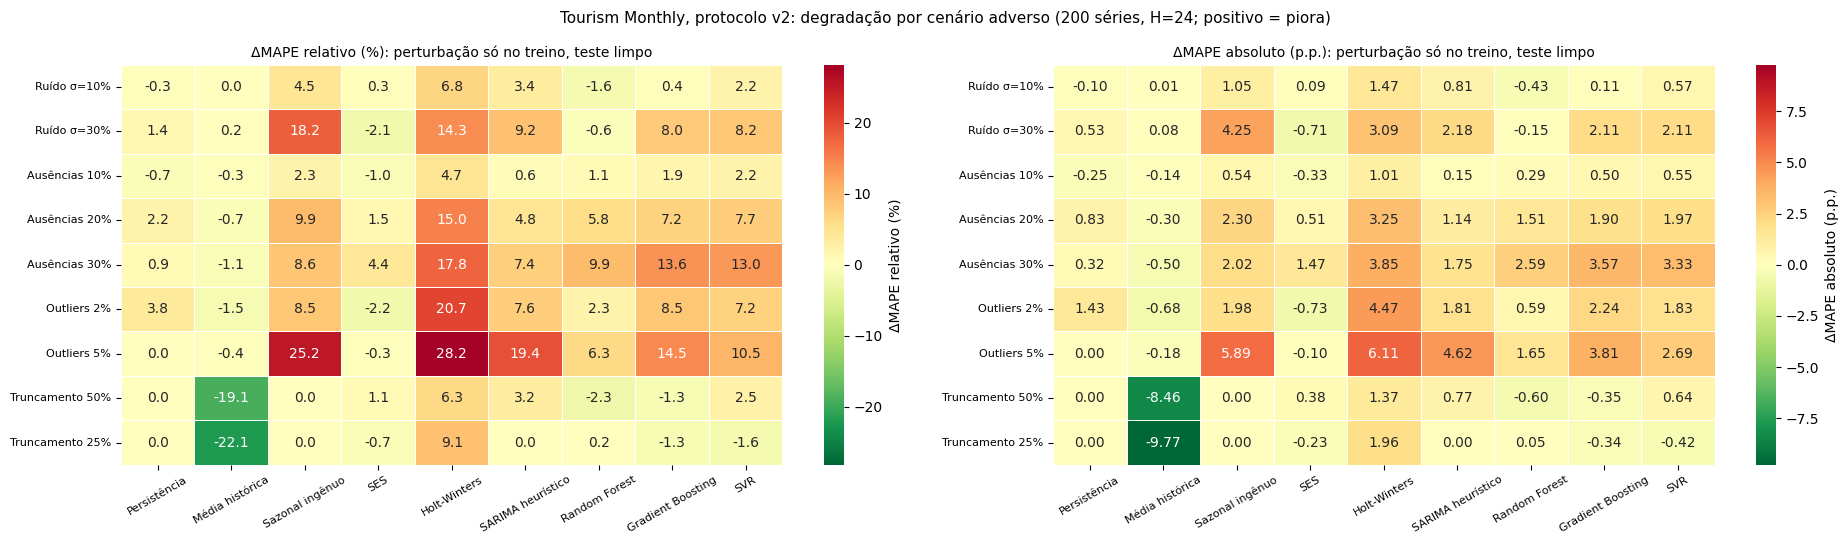

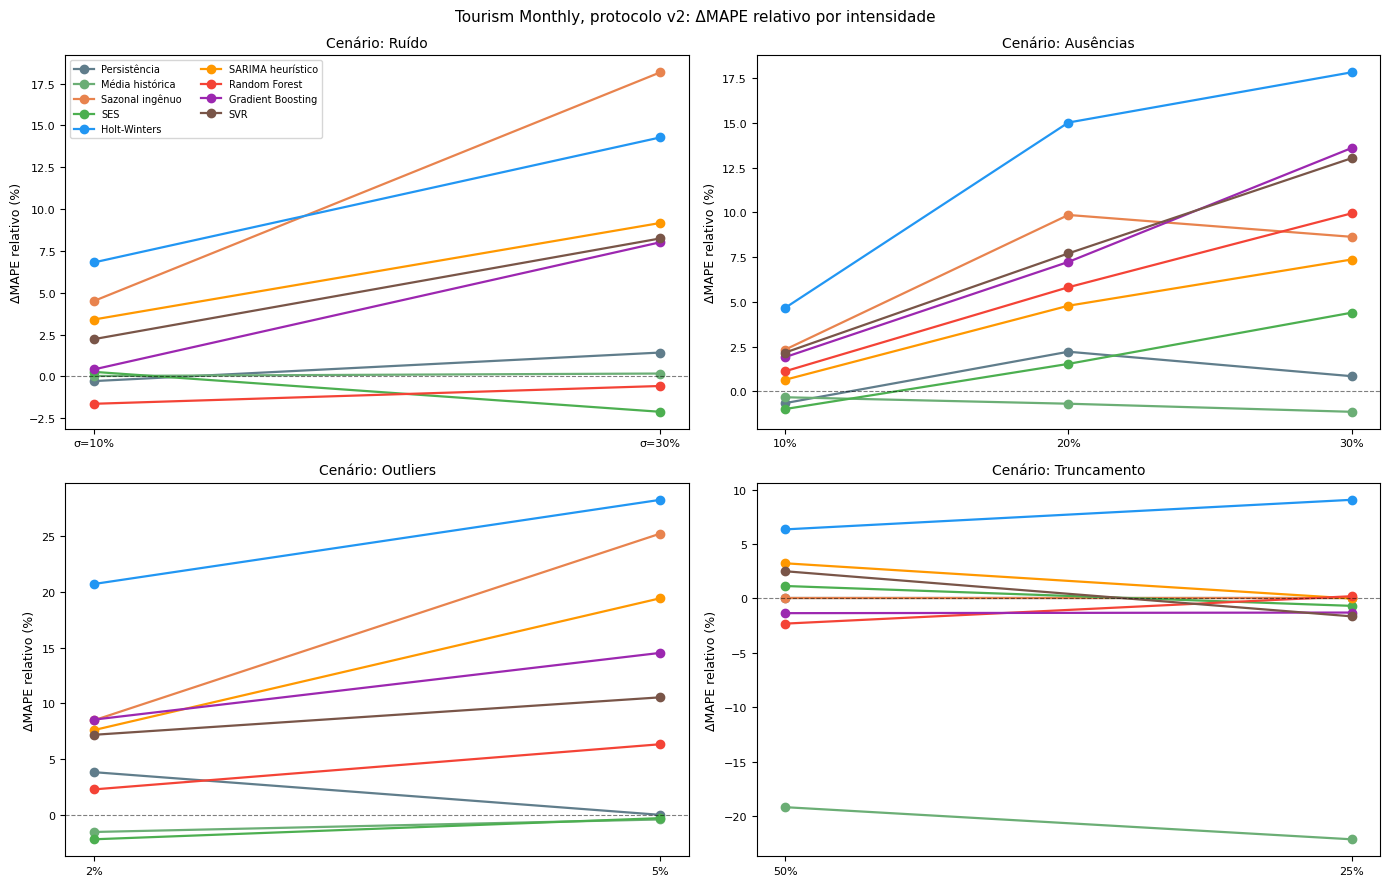

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(19, 5.5))
for ax, tab, titulo, fmt_ in [(axes[0], d_pct, 'ΔMAPE relativo (%)', '.1f'), (axes[1], d_pp, 'ΔMAPE absoluto (p.p.)', '.2f')]:
    lim = np.nanmax(np.abs(tab.values))
    sns.heatmap(tab, annot=True, fmt=fmt_, cmap='RdYlGn_r', center=0, vmin=-lim, vmax=lim, linewidths=0.5,
                linecolor='white', ax=ax, cbar_kws={'label': titulo})
    ax.set_title(f'{titulo}: perturbação só no treino, teste limpo', fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30, labelsize=8); ax.tick_params(axis='y', rotation=0, labelsize=8)
fig.suptitle('Tourism Monthly, protocolo v2: degradação por cenário adverso (200 séries, H=24; positivo = piora)', fontsize=11)
plt.tight_layout(); plt.savefig(DIR_ADV / 'fig_v2_tm_heatmap_delta.png', dpi=150, bbox_inches='tight'); plt.show()

CORES = {'holt_winters': '#2196F3', 'ses': '#4CAF50', 'gbt': '#9C27B0', 'random_forest': '#F44336', 'svr': '#795548',
         'persistence': '#607D8B', 'seasonal_naive': '#E8834E', 'mean': '#6BAE75', 'sarima_heuristic': '#FF9800'}
prog = {'Ruído': ['A_ruido_10pct', 'A_ruido_30pct'], 'Ausências': ['B_ausencias_10pct', 'B_ausencias_20pct', 'B_ausencias_30pct'],
        'Outliers': ['C_outliers_2pct', 'C_outliers_5pct'], 'Truncamento': ['D_trunca_50pct', 'D_trunca_25pct']}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (tp, cs) in zip(axes.flatten(), prog.items()):
    for m in MODELOS:
        ys = [delta[(delta.cenario == c) & (delta.model == m)]['delta_pct'].iloc[0] for c in cs]
        ax.plot([DESC[c].split()[-1] for c in cs], ys, marker='o', color=CORES[m], label=NOMES[m], linewidth=1.6)
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.set_title(f'Cenário: {tp}', fontsize=10); ax.set_ylabel('ΔMAPE relativo (%)', fontsize=9); ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=7, ncol=2)
fig.suptitle('Tourism Monthly, protocolo v2: ΔMAPE relativo por intensidade', fontsize=11)
plt.tight_layout(); plt.savefig(DIR_ADV / 'fig_v2_tm_perfil_robustez.png', dpi=150, bbox_inches='tight'); plt.show()